In [ ]:
import sys
from pathlib import Path
import time
import matplotlib.pyplot as plt

PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir()), Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from qdrant_client import QdrantClient
from qdrant_client.models import VectorParams, Distance, PointStruct
from sentence_transformers import SentenceTransformer
from src.config import settings
import localspelling
from langchain_text_splitters import SentenceTransformersTokenTextSplitter

## 2. Load Model

In [7]:
MODEL_NAME = "sentence-transformers/all-mpnet-base-v2"

model = SentenceTransformer(MODEL_NAME)
TOKEN_LIMIT = model.get_max_seq_length()
TOKENS_PER_CHUNK = TOKEN_LIMIT - 10  # buffer aman

print(f'✅ Model loaded: {MODEL_NAME}')
print(f'📏 Token limit model : {TOKEN_LIMIT}')
print(f'📏 Tokens per chunk  : {TOKENS_PER_CHUNK}')

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 307.04it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Model loaded: sentence-transformers/all-mpnet-base-v2
📏 Token limit model : 384
📏 Tokens per chunk  : 374


## 3. Setup Splitter

In [11]:
splitter = SentenceTransformersTokenTextSplitter(
    model_name=MODEL_NAME,
)

TOKEN_LIMIT = splitter.maximum_tokens_per_chunk

def count_tokens(text):
    """Hitung token via official LangChain API."""
    return splitter.count_tokens(text=text)

print(f'✅ Splitter siap')
print(f'📏 maximum_tokens_per_chunk : {splitter.maximum_tokens_per_chunk}')

# Verifikasi count_tokens berjalan
test_count = count_tokens('hello world')
print(f'🧪 Test count_tokens("hello world") = {test_count} tokens')

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9557.51it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Splitter siap
📏 maximum_tokens_per_chunk : 384
🧪 Test count_tokens("hello world") = 4 tokens


# 4. Data

In [13]:
# ─── Sesuaikan path CSV kamu di sini ─────────────────────────────────────────
FILE_COVER  = '../src/assets/dss_trade_agreements_202602201509.csv'
FILE_DETAIL = '../src/assets/dss_trade_agreement_detail_formatted_202602201508.csv'  
DATA_LIMIT  = None  # set angka (misal 500) untuk batasi data, None = semua
# ─────────────────────────────────────────────────────────────────────────────

dt_cover  = pd.read_csv(FILE_COVER)
dt_detail = pd.read_csv(FILE_DETAIL)

# Merge — sama persis dengan load_data() di ingest.py
df = pd.merge(dt_detail, dt_cover, left_on='rta_id', right_on='id', how='inner')

# Cleaning
df = df.dropna(subset=['article_text'])
print(f'Total data before cleaning : {len(df)}')

df = df.drop_duplicates(subset=['article_text', 'Agreement'])
print(f'Total data after cleaning  : {len(df)}')

if DATA_LIMIT:
    df = df.head(DATA_LIMIT)

print(f'\n📊 Total Data Siap Diproses: {len(df)} baris')

# Statistik panjang karakter (sama seperti ingest.py)
df['total_chars'] = (
    df['Agreement'].astype(str) + ' - ' +
    df['chapter_name'].astype(str) + ' - ' +
    df['article_name'].astype(str) + ': ' +
    df['article_text'].astype(str)
).str.len()

print('\n=== Statistik Panjang Karakter ===')
print(df['total_chars'].describe().round(1))
over_limit = len(df[df['total_chars'] > 3000])
print(f'⚠️  Data di atas 3000 karakter: {over_limit} dari {len(df)} baris')
print('==================================')

df.head(3)

/tmp/ipykernel_21089/3704139902.py:8: DtypeWarning: Columns (13,14) have mixed types. Specify dtype option on import or set low_memory=False.
  dt_detail = pd.read_csv(FILE_DETAIL)


Total data before cleaning : 80619
Total data after cleaning  : 80004

📊 Total Data Siap Diproses: 80004 baris

=== Statistik Panjang Karakter ===
count    80004.0
mean      1249.5
std       1431.5
min         36.0
25%        480.0
50%        839.0
75%       1506.0
max      41984.0
Name: total_chars, dtype: float64
⚠️  Data di atas 3000 karakter: 5993 dari 80004 baris


,id_x,title,chapter_number,chapter_name,article_number,article_name,article_text,filename_x,chapter_id,article_id,...,document_type,parties_escap,desta_id,wits_id,tota_id,aptiad_id,services_schedules,wto_rta_id,deleted_at_y,total_chars
0,28,Russian Federation - Azerbaijan,NaN,Preamble,NaN,Preamble,agreement between the government of and the go...,pta_10.xml,10_1,10_1,...,main,Yes,90,NaN,422.0,43.0,NaN,830.0,NaN,816
1,29,Russian Federation - Azerbaijan,NaN,NaN,ARTICLE 1,NaN,contracting parties shall not apply customs du...,pta_10.xml,10_2,10_2,...,main,Yes,90,NaN,422.0,43.0,NaN,830.0,NaN,1370
2,30,Russian Federation - Azerbaijan,NaN,NaN,ARTICLE 2,NaN,contracting parties shall not directly or indi...,pta_10.xml,10_2,10_3,...,main,Yes,90,NaN,422.0,43.0,NaN,830.0,NaN,803


In [14]:
# Bangun kolom text_to_vector — sama persis dengan logic di process_and_upload()
# Format: '{Agreement} - {chapter_name} - {article_name}: {article_text}'

def build_text_to_vector(row):
    agreement_name = row['Agreement']
    chapter_name   = row['chapter_name'] if pd.notna(row['chapter_name']) else 'General Provisions'
    article_name   = row['article_name']  if pd.notna(row['article_name'])  else ''
    article_text   = row['article_text']
    return f"{agreement_name} - {chapter_name} - {article_name}: {article_text}"

df['text_to_vector'] = df.apply(build_text_to_vector, axis=1)
df['text_token_count'] = df['text_to_vector'].apply(count_tokens)

print('=== Statistik Token text_to_vector ===')
print(df['text_token_count'].describe().round(1))
over_token = len(df[df['text_token_count'] > TOKEN_LIMIT])
print(f'\n⚠️  Teks melebihi {TOKEN_LIMIT} token : {over_token} dari {len(df)} baris')
print('=======================================')

# Preview
df[['Agreement','article_name','text_token_count','text_to_vector']].head(5)

=== Statistik Token text_to_vector ===
count    80004.0
mean       212.2
std        243.4
min         13.0
25%         83.0
50%        142.0
75%        253.0
max       7150.0
Name: text_token_count, dtype: float64

⚠️  Teks melebihi 384 token : 10196 dari 80004 baris


,Agreement,article_name,text_token_count,text_to_vector
0,Russian Federation - Azerbaijan,Preamble,136,Russian Federation - Azerbaijan - Preamble - P...
1,Russian Federation - Azerbaijan,NaN,223,Russian Federation - Azerbaijan - General Prov...
2,Russian Federation - Azerbaijan,NaN,129,Russian Federation - Azerbaijan - General Prov...
3,Russian Federation - Azerbaijan,NaN,264,Russian Federation - Azerbaijan - General Prov...
4,Russian Federation - Azerbaijan,NaN,200,Russian Federation - Azerbaijan - General Prov...


## 6. Proses Chunking

In [16]:
results = []
SPECIAL_TOKENS = 2
for idx, row in df.iterrows():
    full_text            = row['text_to_vector'] 
    original_token_count = row['text_token_count']

    chunks     = splitter.split_text(full_text)
    was_chunked = len(chunks) > 1

    for chunk_idx, chunk in enumerate(chunks):
        chunk_tokens = count_tokens(chunk)
        results.append({
            'row_index'      : idx,
            'Agreement'      : row['Agreement'],
            'article_name'   : row['article_name'] if pd.notna(row['article_name']) else '',
            'chapter_name'   : row['chapter_name'] if pd.notna(row['chapter_name']) else '',
            'original_tokens': original_token_count,
            'was_chunked'    : was_chunked,
            'chunk_index'    : chunk_idx,
            'total_chunks'   : len(chunks),
            'chunk_tokens'   : chunk_tokens,
            'exceeds_limit': (chunk_tokens - SPECIAL_TOKENS) > TOKEN_LIMIT,
            'chunk_text'     : chunk,
        })

result_df = pd.DataFrame(results)
print(f'✅ Total chunks dihasilkan : {len(result_df)}')
print(f'📄 Dari {df.shape[0]} dokumen')
print(f'⚠️  Chunks melebihi limit  : {result_df["exceeds_limit"].sum()}')
result_df[[
    'row_index','Agreement','article_name',
    'original_tokens','was_chunked','chunk_index','total_chunks','chunk_tokens','exceeds_limit'
]].head(20)

✅ Total chunks dihasilkan : 94931
📄 Dari 80004 dokumen
⚠️  Chunks melebihi limit  : 299


,row_index,Agreement,article_name,original_tokens,was_chunked,chunk_index,total_chunks,chunk_tokens,exceeds_limit
0,0,Russian Federation - Azerbaijan,Preamble,136,False,0,1,136,False
1,1,Russian Federation - Azerbaijan,,223,False,0,1,223,False
2,2,Russian Federation - Azerbaijan,,129,False,0,1,129,False
3,3,Russian Federation - Azerbaijan,,264,False,0,1,264,False
4,4,Russian Federation - Azerbaijan,,200,False,0,1,200,False
5,5,Russian Federation - Azerbaijan,,41,False,0,1,41,False
6,6,Russian Federation - Azerbaijan,,32,False,0,1,32,False
7,7,Russian Federation - Azerbaijan,,101,False,0,1,101,False
8,8,Russian Federation - Azerbaijan,,132,False,0,1,132,False
9,9,Russian Federation - Azerbaijan,,53,False,0,1,53,False


In [17]:
over_df = result_df[result_df['exceeds_limit'] == True]

print(f"Total exceeds: {len(over_df)}")
print(f"Token terbesar: {over_df['chunk_tokens'].max()}")
print(f"Rata-rata token chunk bermasalah: {over_df['chunk_tokens'].mean():.1f}")
print()

# Lihat sampel 3 teratas
for _, row in over_df.nlargest(3, 'chunk_tokens').iterrows():
    print(f"Agreement : {row['Agreement']}")
    print(f"Article   : {row['article_name']}")
    print(f"Tokens    : {row['chunk_tokens']}")
    print(f"Text      : {row['chunk_text'][:300]}...")
    print("---")

Total exceeds: 299
Token terbesar: 389
Rata-rata token chunk bermasalah: 388.2

Agreement : GENERAL AGREEMENT ON TARIFFS AND TRADE 1994
Article   : -
Tokens    : 389
Text      : ##ensification or institution respectively of restrictions under paragraph of article xviii the date referred to in paragraph b shall be the date determined by the contracting parties in accordance with the provisions of paragraph b of article xii of this agreement it is recognized that before decid...
---
Agreement : WTO AGREEMENT ON AGRICULTURE
Article   : -
Tokens    : 389
Text      : ##ticulation roads and other means of transport market and port facilities water supply facilities dams and drainage schemes and infrastructural works associated with environmental programmes in all cases the expenditure shall be directed to the provision or construction of capital works only and sh...
---
Agreement : AGREEMENT ON THE APPLICATION OF SPS MEASURES
Article   : -
Tokens    : 389
Text      : ##ootics c for plant hea

## 7. Statistik Token per Chunk

In [20]:
print('=== Statistik Token per Chunk ===')
print(result_df['chunk_tokens'].describe().round(1))
print(f'\nMax token  : {result_df["chunk_tokens"].max()} (limit: {TOKEN_LIMIT})')
print(f'Min token  : {result_df["chunk_tokens"].min()}')
print(f'Rata-rata  : {result_df["chunk_tokens"].mean():.1f}')

result_df['chunk_tokens_clean'] = result_df['chunk_tokens'] - 2  # buat kolom dulu
over = result_df[result_df['chunk_tokens_clean'] > TOKEN_LIMIT]   # baru filter

if len(over) > 0:
    print(f'\n❌ ADA {len(over)} chunk yang melebihi limit!')
    print(over[['row_index','article_name','chunk_tokens','chunk_tokens_clean']])
else:
    print(f'\n✅ Semua chunk aman, tidak ada yang melebihi {TOKEN_LIMIT} token.')

=== Statistik Token per Chunk ===
count    94931.0
mean       187.0
std        118.0
min         13.0
25%         87.0
50%        152.0
75%        281.0
max        389.0
Name: chunk_tokens, dtype: float64

Max token  : 389 (limit: 384)
Min token  : 13
Rata-rata  : 187.0

❌ ADA 299 chunk yang melebihi limit!
       row_index                                       article_name  \
169          148                  Settlement Of Investment Disputes   
440          356                                                  -   
508          396                                                  -   
542          416                                                  -   
593          440  Information About Technical Regulations, Stand...   
...          ...                                                ...   
92411      78505  Settlement Of Investment Disputes Between A Co...   
92412      78505  Settlement Of Investment Disputes Between A Co...   
93930      79861               Rules of Procedure of

## 8. Visualisasi Distribusi Token

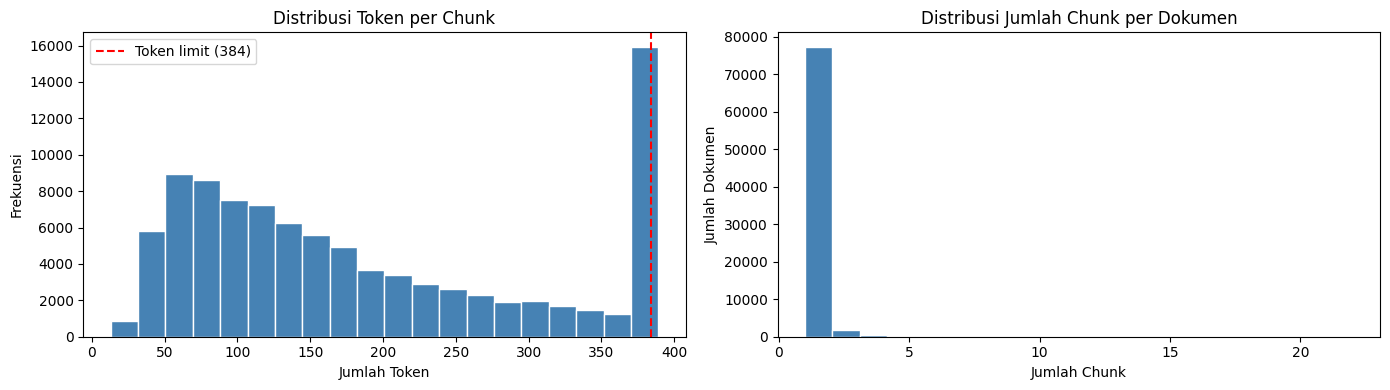

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histogram distribusi token
axes[0].hist(result_df['chunk_tokens'], bins=20, color='steelblue', edgecolor='white')
axes[0].axvline(TOKEN_LIMIT, color='red', linestyle='--', label=f'Token limit ({TOKEN_LIMIT})')
axes[0].set_title('Distribusi Token per Chunk')
axes[0].set_xlabel('Jumlah Token')
axes[0].set_ylabel('Frekuensi')
axes[0].legend()

# Bar: jumlah chunk per dokumen
chunks_per_doc = result_df.groupby('row_index')['chunk_index'].max() + 1

axes[1].hist(chunks_per_doc, bins=20, color='steelblue', edgecolor='white')
axes[1].set_title('Distribusi Jumlah Chunk per Dokumen')
axes[1].set_xlabel('Jumlah Chunk')
axes[1].set_ylabel('Jumlah Dokumen')

plt.tight_layout()
plt.show()

## 9. Inspect Chunk Detail per Dokumen

In [29]:
# Otomatis ambil dokumen pertama yang dipecah jadi >1 chunk
chunked_docs = result_df[result_df['was_chunked'] == True]

if chunked_docs.empty:
    print("Tidak ada dokumen yang dipecah.")
else:
    # Ambil row_index pertama yang was_chunked
    INSPECT_ROW = chunked_docs.iloc[0]['row_index']
    subset = result_df[result_df['row_index'] == INSPECT_ROW]

    print(f'📄 Dokumen  : {subset.iloc[0]["Agreement"]}')
    print(f'📑 Chapter  : {subset.iloc[0]["chapter_name"]}')
    print(f'📝 Article  : {subset.iloc[0]["article_name"]}')
    print(f'🔢 Row index: {INSPECT_ROW}')
    print(f'   Original tokens : {subset.iloc[0]["original_tokens"]}')
    print(f'   Total chunks    : {subset.iloc[0]["total_chunks"]}')
    print()

    for _, c in subset.iterrows():
        print(f'--- Chunk {c["chunk_index"]+1}/{c["total_chunks"]} ({c["chunk_tokens"]} tokens) ---')
        print(c['chunk_text'])
        print()

📄 Dokumen  : Japan - Thailand
📑 Chapter  : Trade In Goods
📝 Article  : Bilateral Safeguard Measures
🔢 Row index: 58
   Original tokens : 1459
   Total chunks    : 5

--- Chunk 1/5 (386 tokens) ---
japan - thailand - trade in goods - bilateral safeguard measures : if an originating good of a party as a result of the elimination or reduction of a customs duty in accordance with article is being imported into the other party in such increased quantities in absolute terms or relative to domestic production and under such conditions that the imports of the originating good constitute a cause of serious injury or threat thereof to a domestic industry of the other party the other party may as a bilateral safeguard measure to the minimum extent necessary to prevent or remedy the serious injury to the domestic industry of the other party and to facilitate its adjustment suspend the further reduction of any rate of customs duty on the originating good provided for in this chapter or increase the

## 10. Ringkasan Akhir

In [30]:
total_docs     = result_df['row_index'].nunique()
total_chunks   = len(result_df)
chunked_docs   = result_df[result_df['was_chunked']]['row_index'].nunique()
safe_chunks    = result_df[~result_df['exceeds_limit']]

print('=' * 40)
print('📋 RINGKASAN CHUNKING')
print('=' * 40)
print(f'Total dokumen          : {total_docs}')
print(f'Dokumen yang di-chunk  : {chunked_docs} ({chunked_docs/total_docs*100:.1f}%)')
print(f'Total chunks           : {total_chunks}')
print(f'Chunks aman (≤{TOKEN_LIMIT} tok) : {len(safe_chunks)} ({len(safe_chunks)/total_chunks*100:.1f}%)')
print(f'Chunks melebihi limit  : {result_df["exceeds_limit"].sum()}')
print(f'Rata-rata token/chunk  : {result_df["chunk_tokens"].mean():.1f}')
print('=' * 40)

📋 RINGKASAN CHUNKING
Total dokumen          : 80004
Dokumen yang di-chunk  : 10104 (12.6%)
Total chunks           : 94931
Chunks aman (≤384 tok) : 94632 (99.7%)
Chunks melebihi limit  : 299
Rata-rata token/chunk  : 187.0
